# CNN, matched filter, and sequential pipeline evaluation

Run `python bin/evaluate_pipeline.py examples/evaluation/simple.json` first.
Set `RUN` below. All three methods use the same injected/control examples and
target splits. Each has precision–recall, a confusion matrix, and an amplitude
sensitivity curve. Controls are benchmark negatives with unknown astrophysical
labels; precision is conditional on this benchmark's class mixture.

CNN amplitude sensitivity measures injected-curve acceptance. Matched-filter and
cascade sensitivity require a detection near the event. The default cascade is
matched filter → CNN, with both gates required. Component scores are computed
once for comparison; sequential survivor counts model the gating, not runtime.


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = Path.cwd() if (Path.cwd() / 'searchlight').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
RUN = ROOT / 'evaluation_runs/full-evaluation'  # base name; newest completed numbered run is selected
candidates = [RUN, *RUN.parent.glob(RUN.name + '-[0-9][0-9][0-9]*')]
completed = [p for p in candidates if (p / 'complete.json').is_file()]
if completed:
    RUN = max(completed, key=lambda p: (p / 'complete.json').stat().st_mtime_ns)
RESULTS = RUN / 'results'
if not (RUN / 'complete.json').exists():
    raise RuntimeError(f'No completed evaluation at {RUN}; run the bin script first or select a finished run.')
load = lambda name: json.loads((RESULTS / f'{name}.json').read_text())
metrics, scores, events = load('metrics'), load('scores'), load('event_details')
run, sensitivity = load('run'), load('amplitude_recovery')
manifest = load('manifest')
print('Loaded:', RUN)

Loaded: /home/anm1u24/Code/astrosearchlight/evaluation_runs/full-evaluation-006


## Physical parameters of the injected profiles

Corner plots show the **actual saved draws**, counting each target/shape once,
regardless of how many amplitudes were injected. Diagonal panels show counts;
lower panels show individual draws and their pairwise relationships. Colours
separate tuning and test profiles. With this small sample, these are scatter
plots and histograms rather than smoothed density contours.

Plots are split into orbital, stellar, and duration parameters for readability.
Axes marked $\log_{10}$ use base-10 logarithms in the indicated units.
Lens mass is `Macc`; source mass is `Mcomp`. Source radius and temperature follow
the simulator's stellar relations, so their correlations are expected. Local
crossing time and measured exposure-averaged FWHM are distinct quantities.

These draws are conditional on lensing, no Roche-lobe overflow, and an isolated,
adequately sampled event. Source properties are not fitted to the background
star. Physical parameters describe the **unscaled shape**: the final plot shows
how those shapes were multiplied to reach the requested injected amplitudes.
Figures are exported as PNG and PDF under the run's `results` directory.

The full proposal also records distance; distance does not determine the measured
noise of the real background. The run records whether amplitude means the sampled
maximum (pilot) or the reference exposure-averaged peak independent of gaps (full).

New generation draws **both source and lens masses log-uniformly**, before physical rejection. Plots always use the saved run: reusing old injections preserves their original mass distribution.


800 generated target/shape profiles across 100 backgrounds
  test: 480 profiles, 60 backgrounds
  tuning: 320 profiles, 40 backgrounds


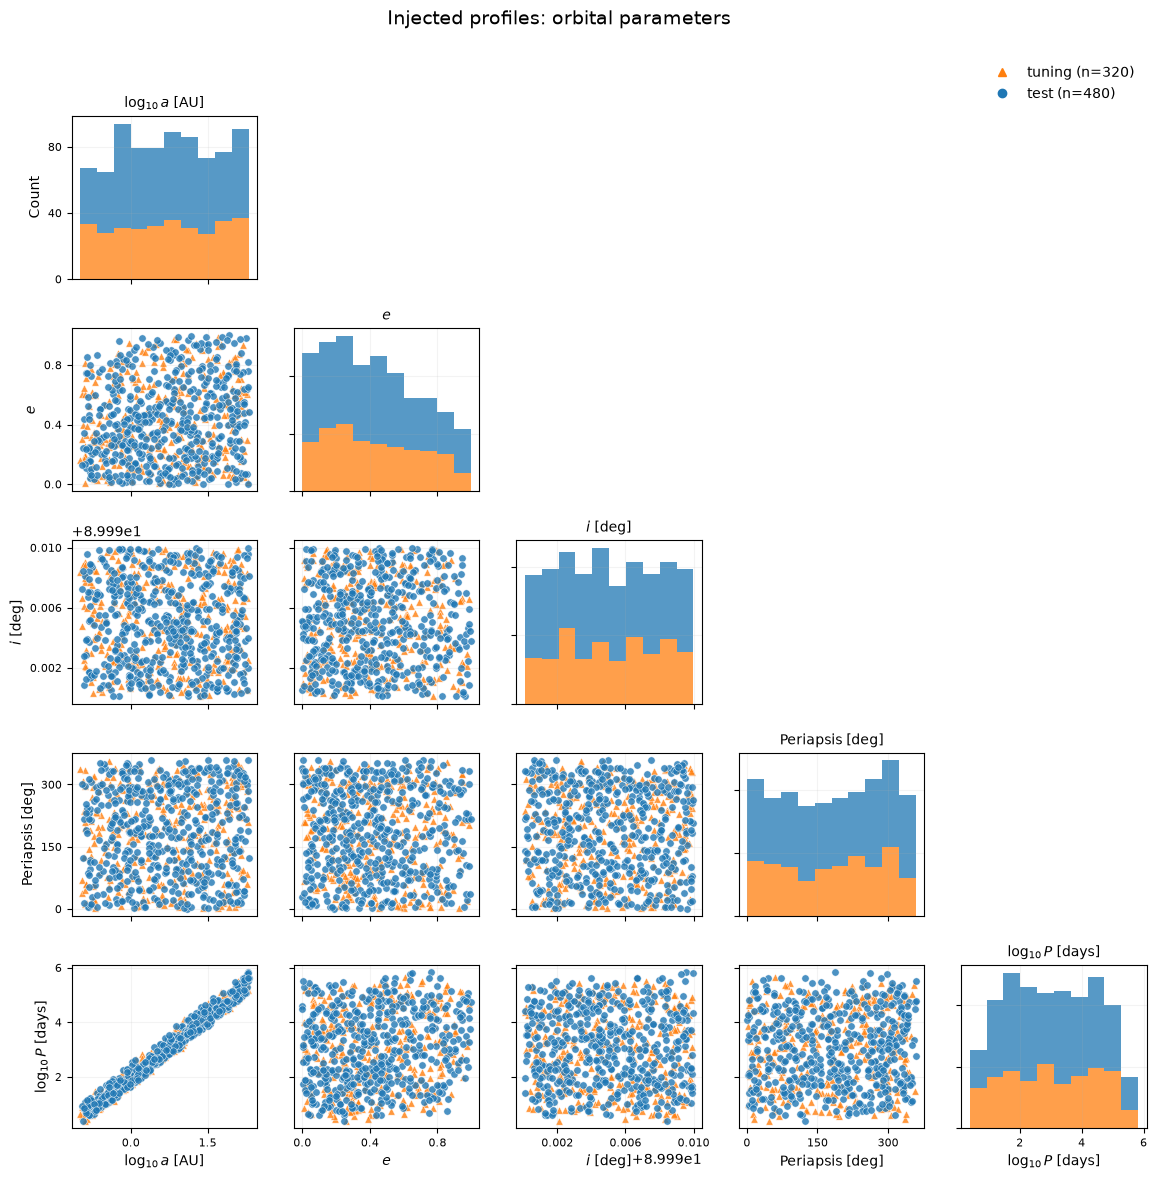

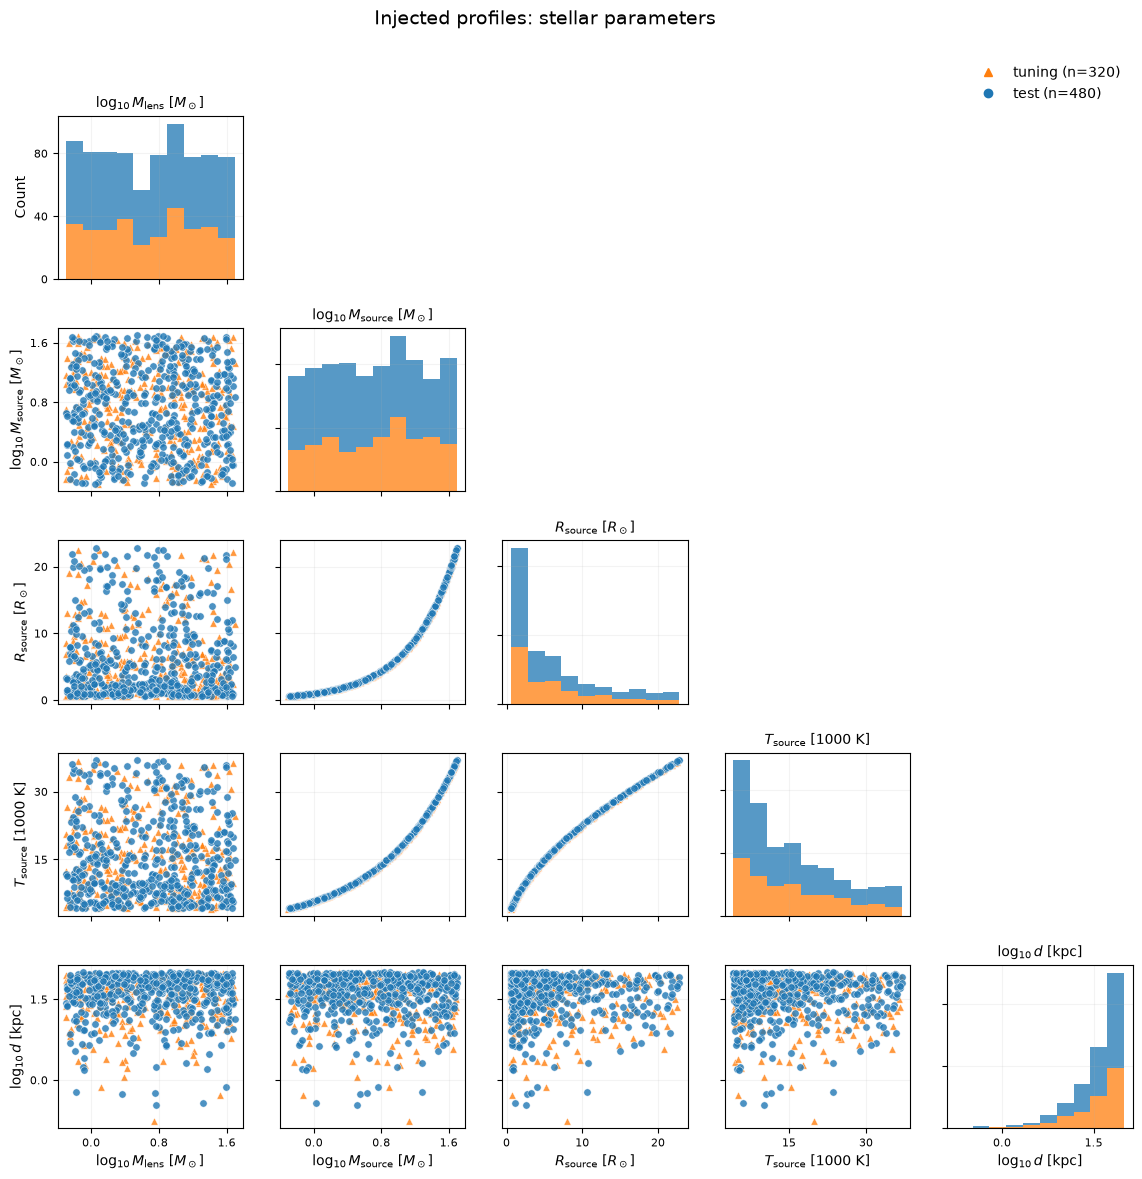

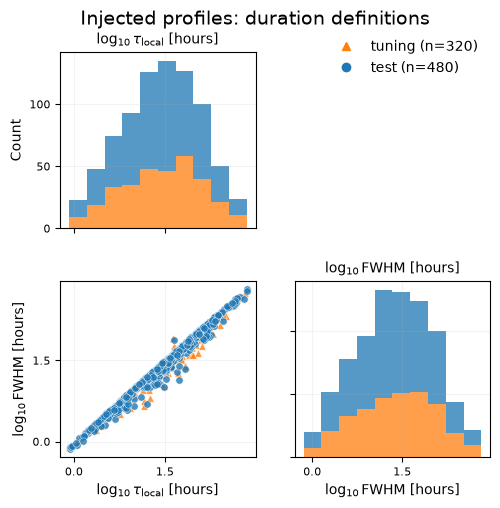

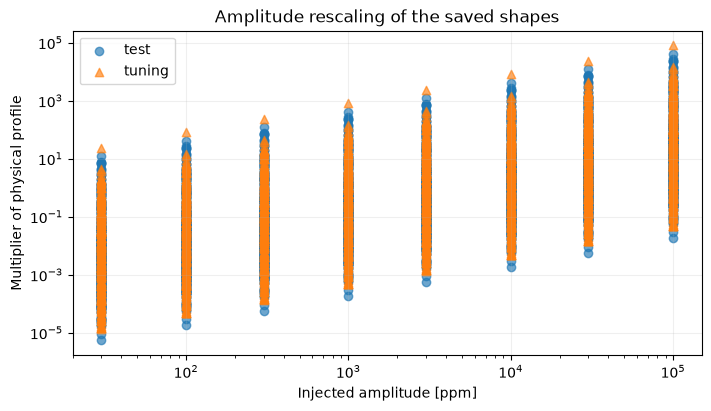

In [2]:
# One row per generated target/shape, not per amplitude variant.
profile_records = manifest.get('metadata', {}).get('profiles', [])
sample_records = {s['sample_id']: s for s in manifest['samples']}
physical_rows = []
for profile in profile_records:
    p = profile['physical_parameters']
    original = sample_records[profile['sample_id']]
    physical_rows.append({
        'background': profile['sample_id'], 'shape': profile['shape'], 'split': original['split'],
        'Semi-major axis (AU)': p['a'], 'Lens mass (solar masses)': p['Macc'],
        'Source mass (solar masses)': p['Mcomp'], 'Source radius (solar radii)': p['Rcomp'],
        'Source temperature (K)': p['Teff'], 'Eccentricity': p['e'],
        'Inclination (deg)': np.degrees(p['i']),
        'Periapsis phase (deg)': np.degrees(p['periapsis_phase']),
        'Orbital period (days)': p['period_days'],
        'Local crossing estimate (hours)': p['duration_days'] * 24,
        **({'Distance (kpc)': p['d']} if 'd' in p else {}),
        'Measured FWHM (hours)': profile['fwhm_days'] * 24,
    })
physical_profiles = pd.DataFrame(physical_rows)
if physical_profiles.empty:
    print('No per-profile physical parameters were saved in this run.')
else:
    print(f"{len(physical_profiles)} generated target/shape profiles across "
          f"{physical_profiles['background'].nunique()} backgrounds")
    for split, group in physical_profiles.groupby('split'):
        print(f"  {split}: {len(group)} profiles, {group['background'].nunique()} backgrounds")


def parameter_corner(frame, columns, labels, title, filename):
    """Counts and raw pairwise draws, without a density estimate for sparse samples."""
    from matplotlib.ticker import MaxNLocator
    from matplotlib.lines import Line2D
    colours = {'tuning': 'tab:orange', 'test': 'tab:blue'}
    markers = {'tuning': '^', 'test': 'o'}
    splits = [split for split in ['tuning', 'test'] if (frame['split'] == split).any()]
    size = len(columns)
    fig, axes = plt.subplots(size, size, figsize=(2.5 * size, 2.5 * size), squeeze=False)
    for i, y in enumerate(columns):
        for j, x in enumerate(columns):
            ax = axes[i, j]
            if j > i:
                ax.set_visible(False)
                continue
            if i == j:
                finite = frame[x].to_numpy(dtype=float)
                finite = finite[np.isfinite(finite)]
                bins = np.histogram_bin_edges(finite, bins=min(10, max(4, int(np.sqrt(len(finite))))))
                ax.hist([frame.loc[frame['split'] == split, x].dropna() for split in splits],
                        bins=bins, stacked=True, color=[colours[split] for split in splits], alpha=.75)
                ax.yaxis.set_major_locator(MaxNLocator(integer=True, nbins=3))
                ax.set_title(labels[j], fontsize=10)
            else:
                for split in splits:
                    selected = frame[frame['split'] == split]
                    ax.scatter(selected[x], selected[y], color=colours[split], marker=markers[split],
                               s=28, alpha=.8, edgecolors='white', linewidths=.4)
                ax.yaxis.set_major_locator(MaxNLocator(nbins=3))
            ax.xaxis.set_major_locator(MaxNLocator(nbins=3))
            ax.tick_params(labelsize=8, labelbottom=i == size - 1, labelleft=j == 0)
            if i == size - 1:
                ax.set_xlabel(labels[j], fontsize=10)
            if j == 0:
                ax.set_ylabel('Count' if i == j else labels[i], fontsize=10)
            ax.grid(alpha=.15)
    handles = [Line2D([], [], color=colours[split], marker=markers[split], linestyle='',
                      label=f"{split} (n={(frame['split'] == split).sum()})") for split in splits]
    fig.suptitle(title, fontsize=14, y=.995)
    fig.legend(handles=handles, loc='upper right', bbox_to_anchor=(.97, .96), frameon=False)
    fig.subplots_adjust(left=.11, bottom=.10, top=.91, right=.97, hspace=.30, wspace=.20)
    for suffix in ['png', 'pdf']:
        fig.savefig(RESULTS / f'{filename}.{suffix}', dpi=160, bbox_inches='tight')
    plt.show()


if not physical_profiles.empty:
    corner_data = physical_profiles.copy()
    for column in ['Semi-major axis (AU)', 'Lens mass (solar masses)', 'Source mass (solar masses)',
                   'Orbital period (days)', 'Local crossing estimate (hours)', 'Measured FWHM (hours)']:
        corner_data['log ' + column] = np.log10(corner_data[column])
    corner_data['Source temperature (1000 K)'] = corner_data['Source temperature (K)'] / 1000
    parameter_corner(corner_data,
        ['log Semi-major axis (AU)', 'Eccentricity', 'Inclination (deg)',
         'Periapsis phase (deg)', 'log Orbital period (days)'],
        [r'$\log_{10} a$ [AU]', r'$e$', r'$i$ [deg]', 'Periapsis [deg]', r'$\log_{10} P$ [days]'],
        'Injected profiles: orbital parameters', 'parameter_corner_orbits')
    stellar_columns = ['log Lens mass (solar masses)', 'log Source mass (solar masses)',
                       'Source radius (solar radii)', 'Source temperature (1000 K)']
    stellar_labels = [r'$\log_{10} M_\mathrm{lens}$ [$M_\odot$]', r'$\log_{10} M_\mathrm{source}$ [$M_\odot$]',
                      r'$R_\mathrm{source}$ [$R_\odot$]', r'$T_\mathrm{source}$ [1000 K]']
    if 'Distance (kpc)' in corner_data:
        corner_data['log Distance (kpc)'] = np.log10(corner_data['Distance (kpc)'])
        stellar_columns.append('log Distance (kpc)')
        stellar_labels.append(r'$\log_{10} d$ [kpc]')
    parameter_corner(corner_data, stellar_columns, stellar_labels,
        'Injected profiles: stellar parameters', 'parameter_corner_stars')
    parameter_corner(corner_data,
        ['log Local crossing estimate (hours)', 'log Measured FWHM (hours)'],
        [r'$\log_{10} \tau_\mathrm{local}$ [hours]', r'$\log_{10} \mathrm{FWHM}$ [hours]'],
        'Injected profiles: duration definitions', 'parameter_corner_durations')

amplitude_rows = [{
    'split': s['split'], 'amplitude_ppm': s['parameters']['amplitude'] * 1e6,
    'profile_multiplier': s['parameters']['amplitude_scale'],
} for s in manifest['samples'] if s.get('parent_id') and 'amplitude_scale' in s['parameters']]
if amplitude_rows:
    amplitude_data = pd.DataFrame(amplitude_rows)
    fig, ax = plt.subplots(figsize=(7, 4), layout='constrained')
    for split, group in amplitude_data.groupby('split'):
        ax.scatter(group['amplitude_ppm'], group['profile_multiplier'],
                   color={'tuning': 'tab:orange', 'test': 'tab:blue'}[split],
                   marker={'tuning': '^', 'test': 'o'}[split], alpha=.65, label=split)
    ax.set(xscale='log', yscale='log', xlabel='Injected amplitude [ppm]',
           ylabel='Multiplier of physical profile', title='Amplitude rescaling of the saved shapes')
    ax.legend(); ax.grid(alpha=.2)
    for suffix in ['png', 'pdf']:
        fig.savefig(RESULTS / f'parameter_amplitude_scaling.{suffix}', dpi=160)
    plt.show()


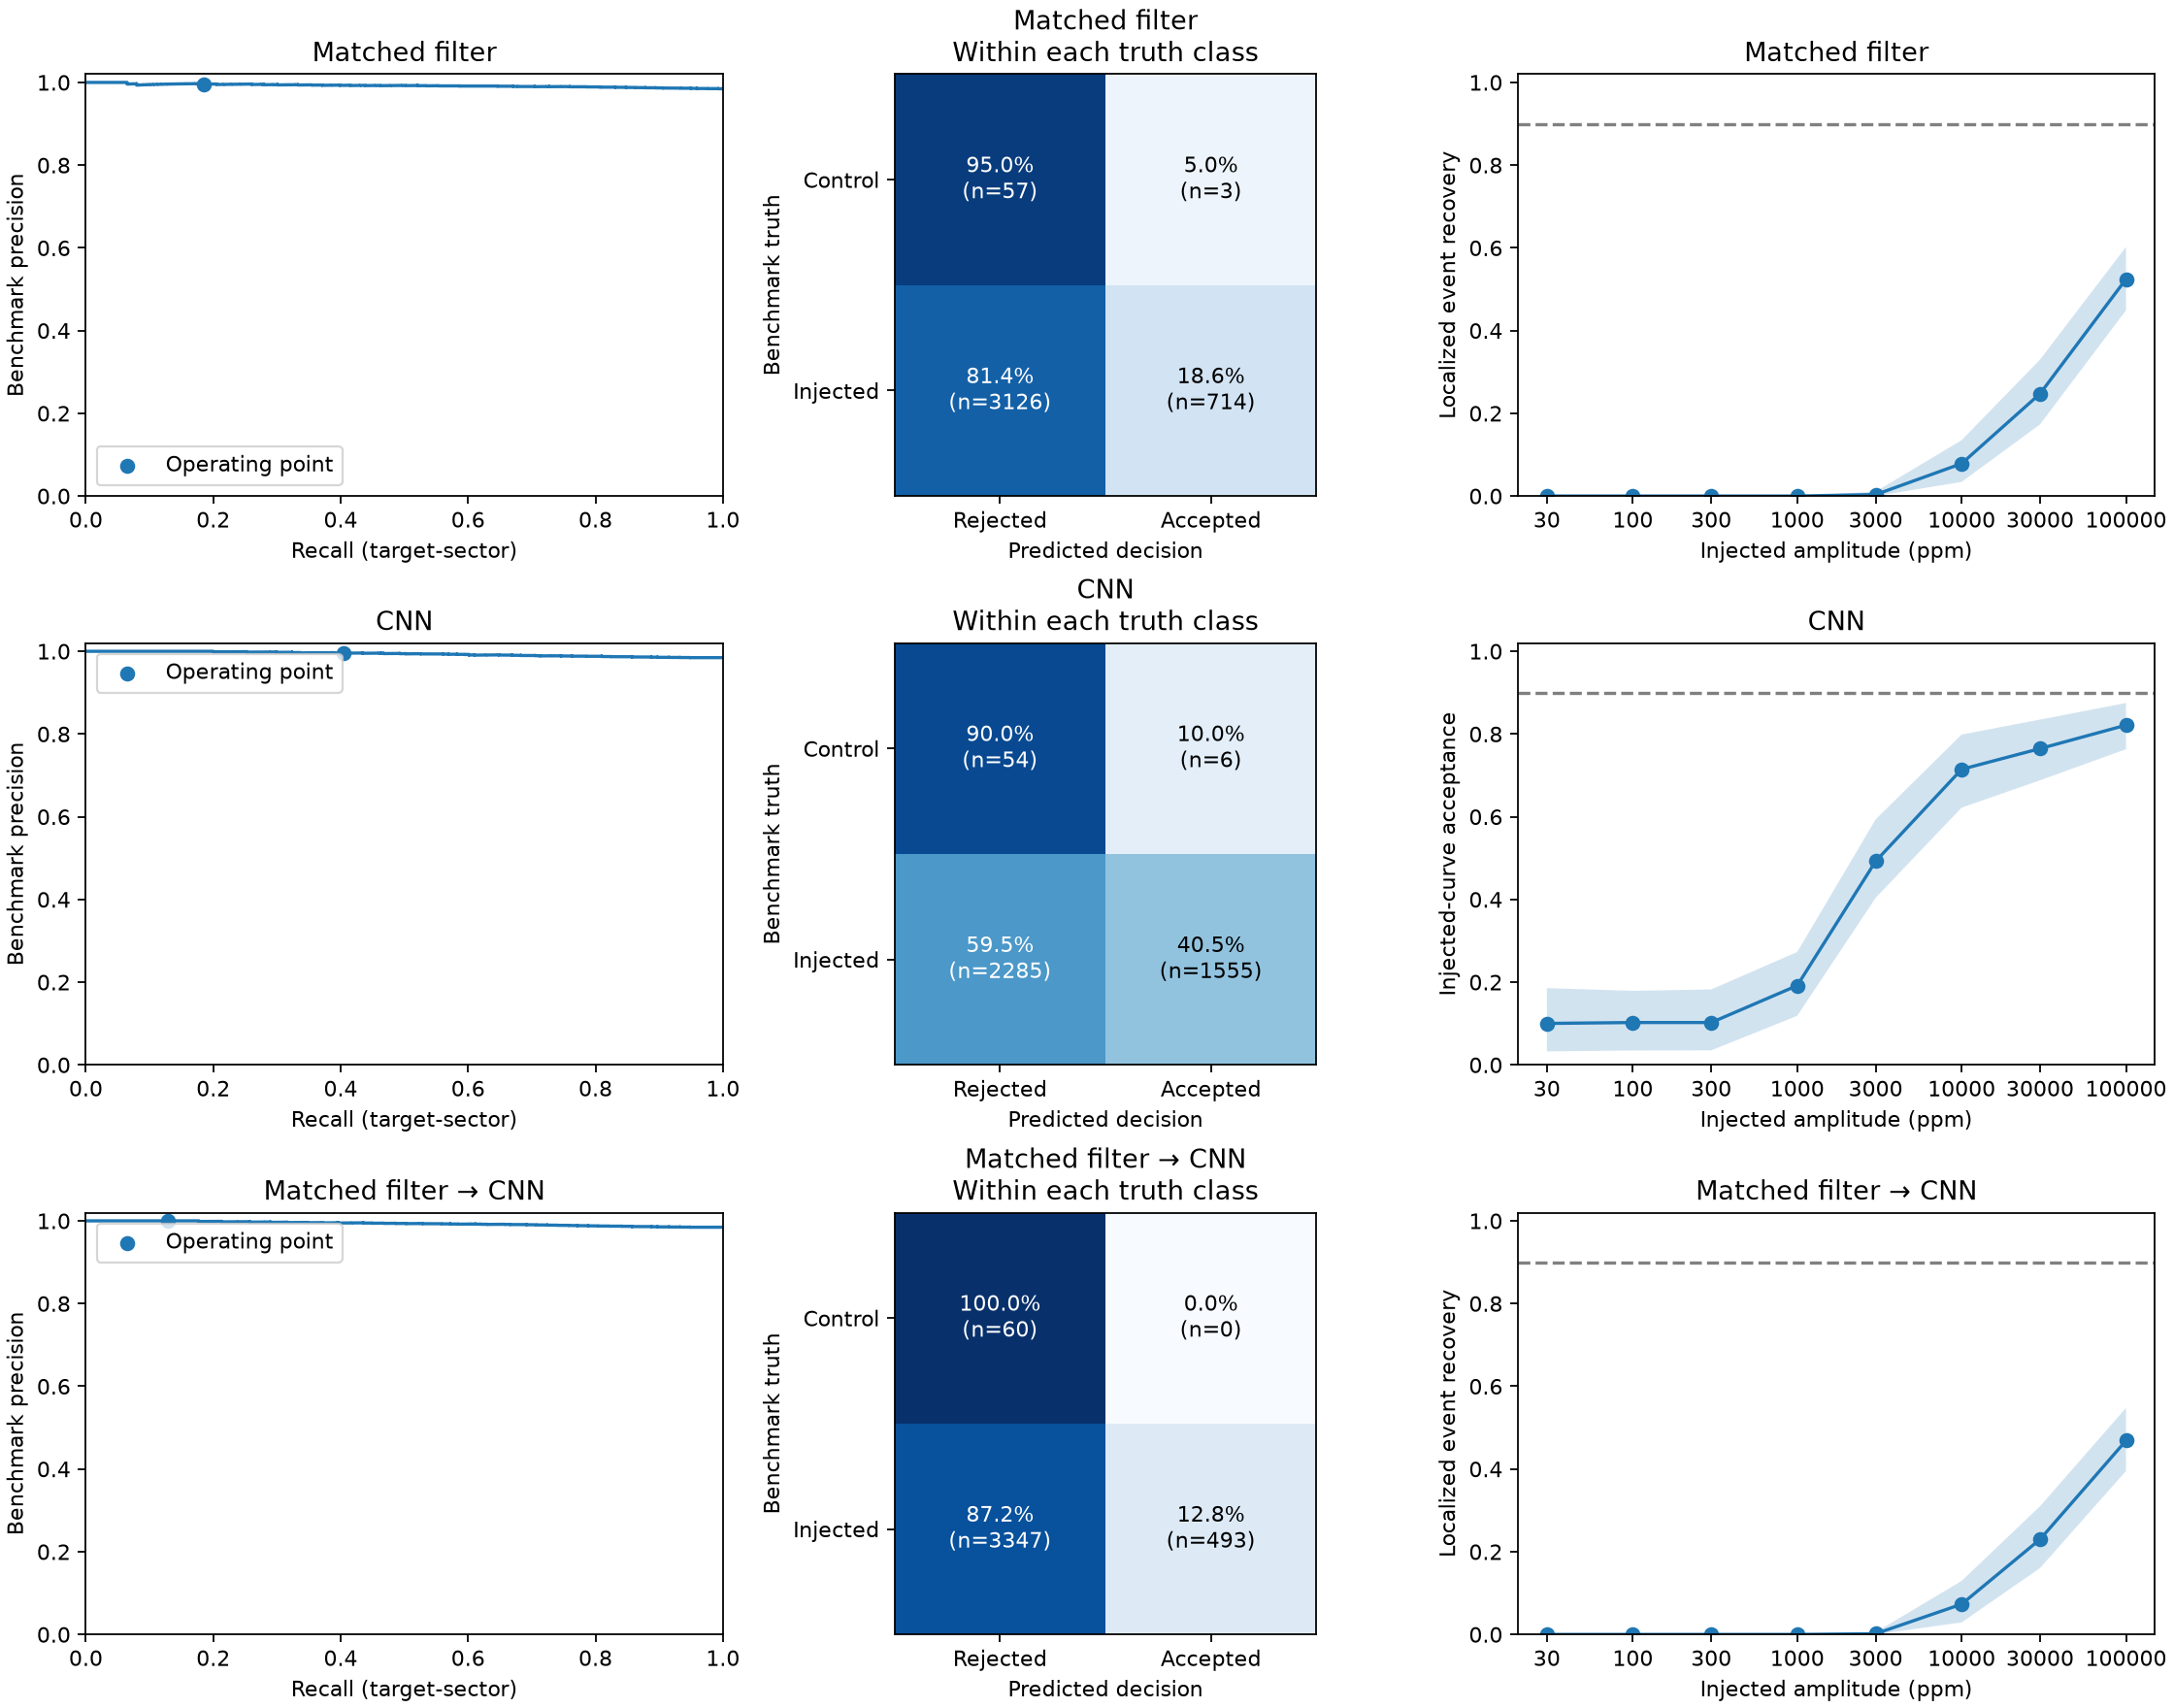

In [3]:
# Rebuild summaries/figures from saved scores, including older completed runs.
# No detector or CNN inference is repeated.
from searchlight.evaluation.simple import render
render(RESULTS)
sensitivity = load('amplitude_recovery')
labels = {'matched_filter': 'Matched filter', 'cnn': 'CNN',
          'combined': 'Matched filter → CNN' if run['pipeline_order'] == 'matched_filter_then_cnn' else 'CNN → matched filter'}
display(Image(filename=str(RESULTS / 'simple_evaluation.png')))


## Operating points and sequential gates

Thresholds are chosen on tuning targets only. All three confusion matrices use
the full test set. The combined PR curve sweeps the joint standardized threshold
margin; the operating point requires both fixed component gates. Stage counts
below show how many curves survive each gate in the configured sequence.


In [4]:
print('Component thresholds:', run['thresholds'])
composition = pd.DataFrame([{'split': split,
    'targets': len({r['group_id'] for r in scores if r['split'] == split}),
    'injected_examples': sum(r['truth'] == 1 for r in scores if r['split'] == split),
    'controls': sum(r['truth'] == 0 for r in scores if r['split'] == split)}
    for split in ['tuning', 'test']])
display(composition)
print('Confusion matrices: ROWS are benchmark truth; COLUMNS are predicted decisions.')
test_composition = composition.set_index('split').loc['test']
ratio = test_composition['injected_examples'] / test_composition['controls']
all_accepted_precision = test_composition['injected_examples'] / (test_composition['injected_examples'] + test_composition['controls'])
print(f'Test mixture: {ratio:g} injected curves per control. Accepting every curve would give '
      f'{all_accepted_precision:.1%} benchmark precision; this is not survey precision.')
decisions = []
for key, label in labels.items():
    tn, fp, fn, tp = np.asarray(metrics[key]['test']['confusion_matrix']).ravel()
    decisions.append({'method': label, 'controls_rejected': tn, 'controls_accepted': fp,
                      'injections_rejected': fn, 'injections_accepted': tp,
                      'all_rejected': fp+tp == 0, 'all_accepted': tn+fn == 0})
display(pd.DataFrame(decisions))
display(pd.DataFrame([{'method': label,
    'recall': metrics[key]['test']['recall'], 'benchmark_precision': metrics[key]['test']['precision'],
    'control_false_positive_fraction': metrics[key]['test']['false_positive_rate'],
    'recall_95pct': metrics[key]['test'].get('uncertainty', {}).get('intervals', {}).get('recall'),
    'precision_95pct': metrics[key]['test'].get('uncertainty', {}).get('intervals', {}).get('precision')}
    for key, label in labels.items()]))
for key, label in labels.items():
    print(label)
    display(pd.DataFrame(metrics[key]['test']['confusion_matrix'],
                         index=['Control truth', 'Injected truth'], columns=['Predicted rejected', 'Predicted accepted']))
    display(pd.DataFrame(metrics[key]['test']['confusion_row_normalized'],
                         index=['Control truth', 'Injected truth'],
                         columns=['Predicted rejected', 'Predicted accepted']).map(
                             lambda value: 'undefined' if value is None else f'{value:.1%}'))
attrition = load('attrition')
display(pd.DataFrame([{'split': split, 'order': ' → '.join(value['order']),
    'input': value['input_rows'], 'after_first_gate': value['after_first'],
    'after_second_gate': value['after_second']} for split, value in attrition.items()]))


Component thresholds: {'matched_filter': 272.0353712495457, 'cnn': 0.6683873156067258, 'combined': 0.0}


,split,targets,injected_examples,controls
0,tuning,40,2560,40
1,test,60,3840,60


Confusion matrices: ROWS are benchmark truth; COLUMNS are predicted decisions.
Test mixture: 64 injected curves per control. Accepting every curve would give 98.5% benchmark precision; this is not survey precision.


,method,controls_rejected,controls_accepted,injections_rejected,injections_accepted,all_rejected,all_accepted
0,Matched filter,57,3,3126,714,False,False
1,CNN,54,6,2285,1555,False,False
2,Matched filter → CNN,60,0,3347,493,False,False


,method,recall,benchmark_precision,control_false_positive_fraction,recall_95pct,precision_95pct
0,Matched filter,0.185938,0.995816,0.05,"[0.14061197916666668, 0.24222656249999996]","[0.9926614101046671, 1.0]"
1,CNN,0.404948,0.996156,0.10,"[0.34453125, 0.46772135416666666]","[0.9937030398840196, 0.9985857470335351]"
2,Matched filter → CNN,0.128385,1.000000,0.00,"[0.10494791666666667, 0.15287109375]","[1.0, 1.0]"


Matched filter


... (5 outputs left out)

Matched filter → CNN


,Predicted rejected,Predicted accepted
Control truth,60,0
Injected truth,3347,493


,Predicted rejected,Predicted accepted
Control truth,100.0%,0.0%
Injected truth,87.2%,12.8%


,split,order,input,after_first_gate,after_second_gate
0,tuning,matched_filter → cnn,2600,474,299
1,test,matched_filter → cnn,3900,717,493


## Confusion matrices by injected amplitude

Each panel uses one saved injected amplitude as a bin, with the same uninjected
controls repeated in every panel. Cells show counts and percentages within each
truth row, using a common 0–100% colour scale. These are light-curve acceptance
decisions at the saved operating thresholds; they do not require event localization.
Change `AMPLITUDE_SPLIT` to inspect tuning results instead of the held-out test set.


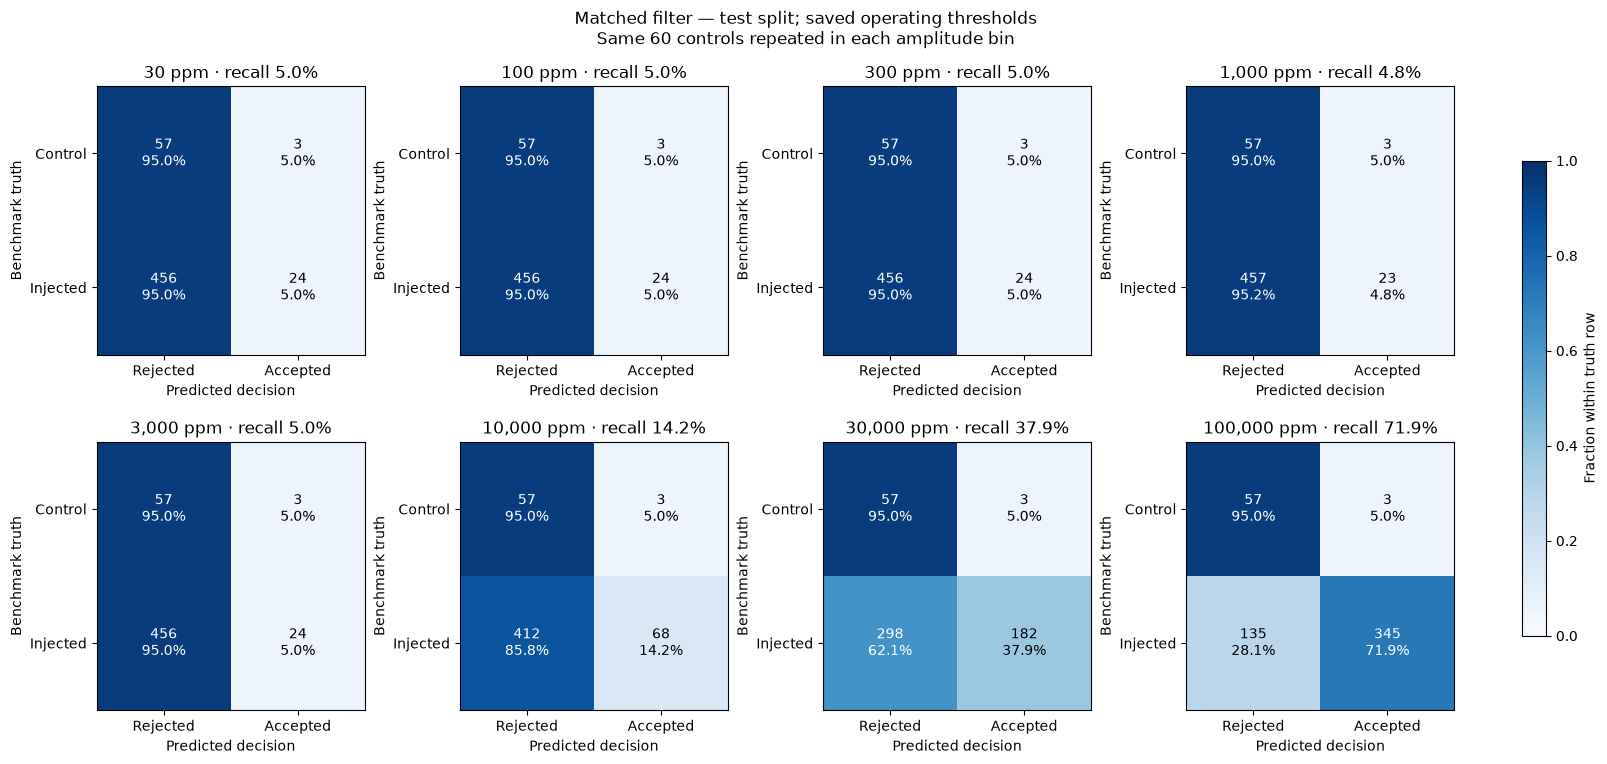

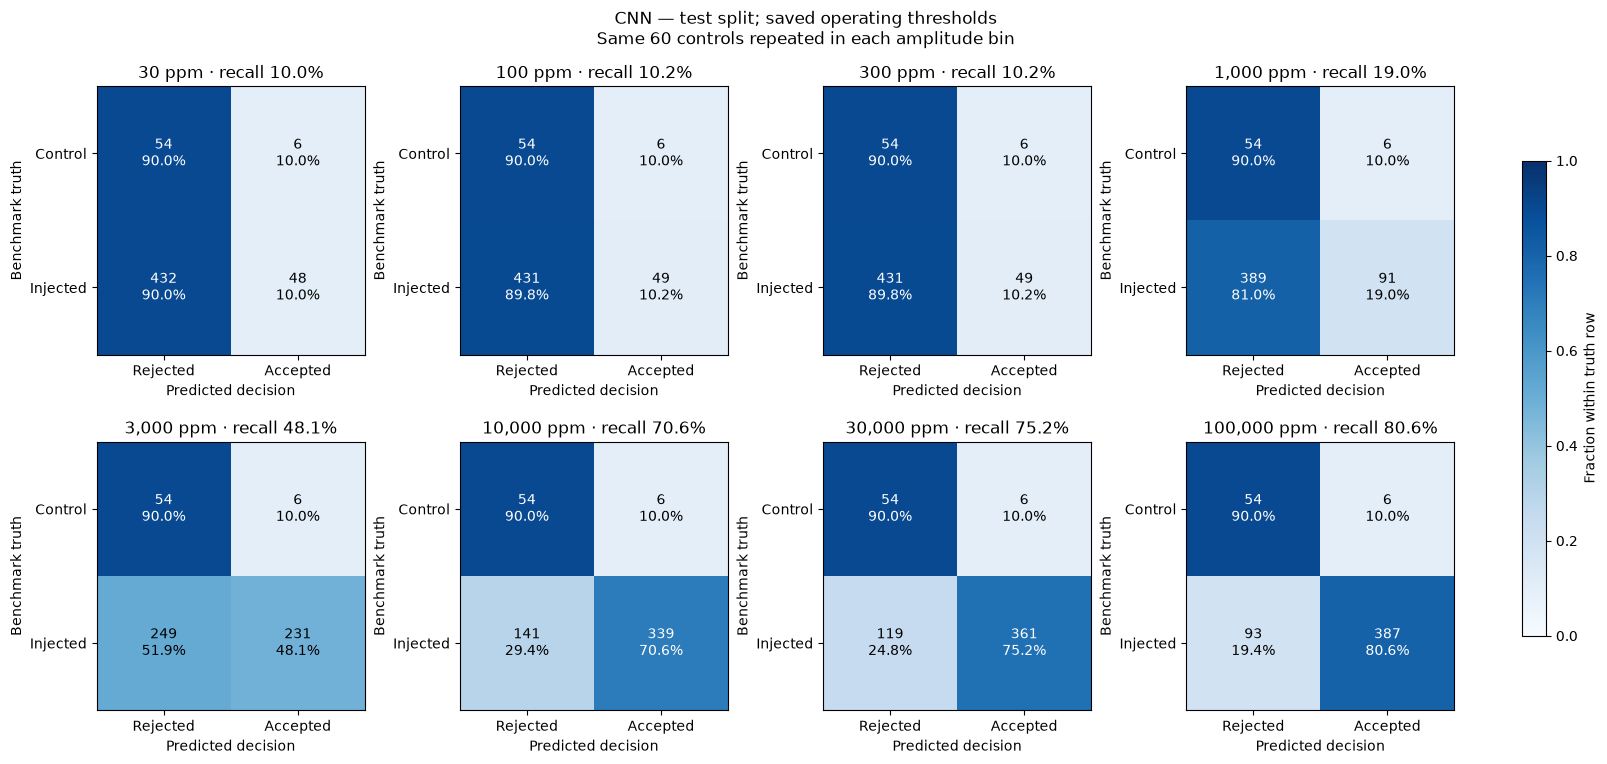

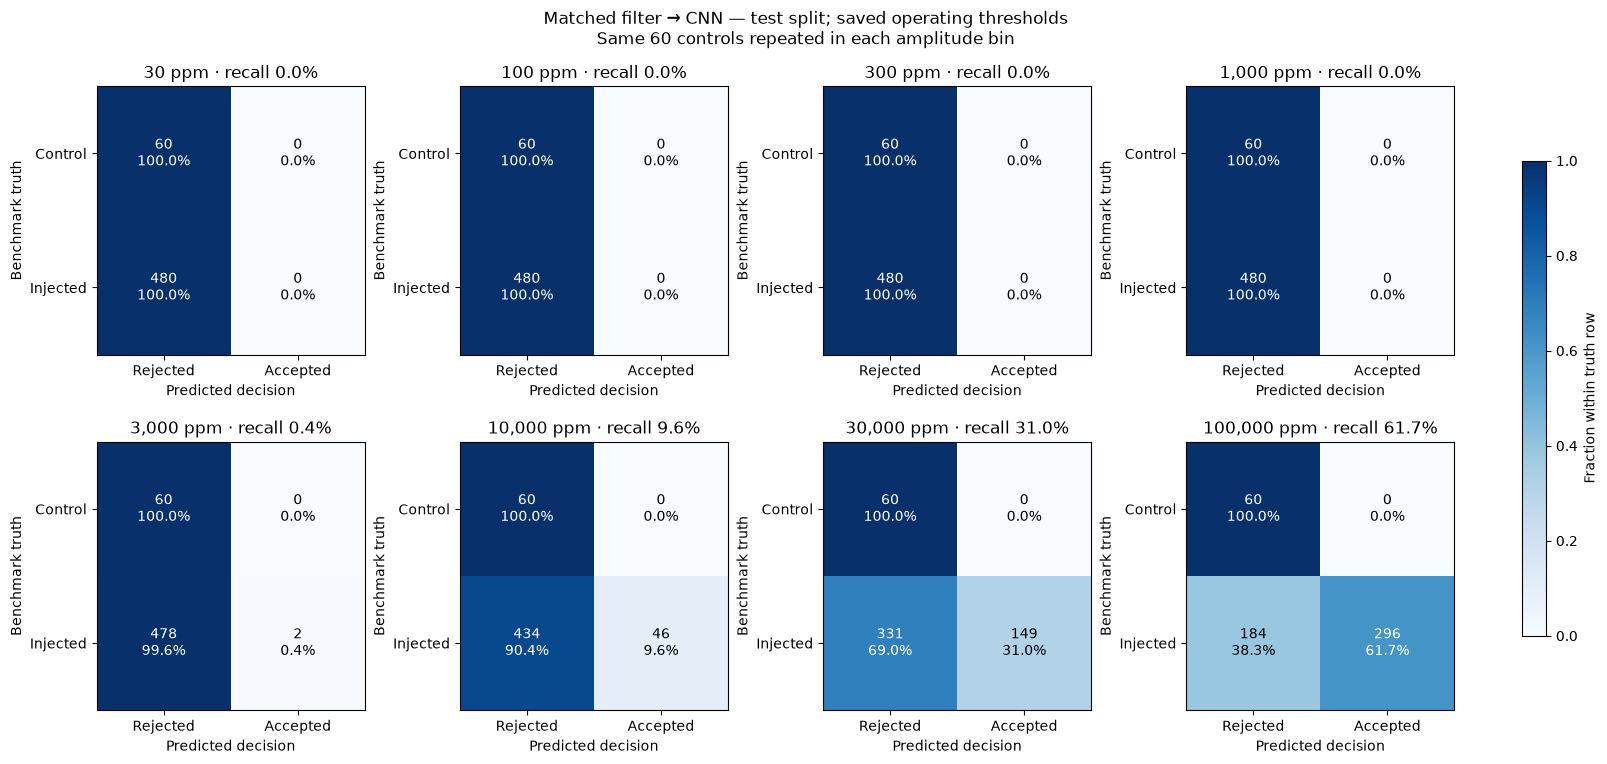

,method,amplitude_ppm,tn,fp,fn,tp,recall
0,Matched filter,30.0,57,3,456,24,0.050000
1,Matched filter,100.0,57,3,456,24,0.050000
2,Matched filter,300.0,57,3,456,24,0.050000
3,Matched filter,1000.0,57,3,457,23,0.047917
4,Matched filter,3000.0,57,3,456,24,0.050000
5,Matched filter,10000.0,57,3,412,68,0.141667
6,Matched filter,30000.0,57,3,298,182,0.379167
7,Matched filter,100000.0,57,3,135,345,0.718750
8,CNN,30.0,54,6,432,48,0.100000
9,CNN,100.0,54,6,431,49,0.102083


In [5]:
AMPLITUDE_SPLIT = 'test'
amplitude_rows = [r for r in scores if r['split'] == AMPLITUDE_SPLIT]
amplitude_controls = [r for r in amplitude_rows if r['truth'] == 0]
amplitude_injections = [r for r in amplitude_rows
                        if r['truth'] == 1 and r.get('parameters', {}).get('amplitude') is not None]
amplitudes_ppm = sorted({round(r['parameters']['amplitude'] * 1e6, 6)
                         for r in amplitude_injections})
amplitude_confusion_rows = []
if not amplitudes_ppm:
    print('No saved injected amplitudes for this split.')
else:
    for key, label in labels.items():
        columns = min(4, len(amplitudes_ppm))
        rows = int(np.ceil(len(amplitudes_ppm) / columns))
        fig, axes = plt.subplots(rows, columns, figsize=(4 * columns, 3.8 * rows),
                                 squeeze=False, constrained_layout=True)
        for ax, amplitude_ppm in zip(axes.flat, amplitudes_ppm):
            injections = [r for r in amplitude_injections
                          if round(r['parameters']['amplitude'] * 1e6, 6) == amplitude_ppm]
            tn = sum(not r[key]['accepted'] for r in amplitude_controls)
            fp = len(amplitude_controls) - tn
            tp = sum(bool(r[key]['accepted']) for r in injections)
            fn = len(injections) - tp
            counts = np.array([[tn, fp], [fn, tp]])
            totals = counts.sum(axis=1, keepdims=True)
            fractions = np.divide(counts, totals, out=np.full((2, 2), np.nan), where=totals > 0)
            im = ax.imshow(fractions, vmin=0, vmax=1, cmap='Blues')
            for (i, j), count in np.ndenumerate(counts):
                percent = f'{fractions[i, j]:.1%}' if totals[i, 0] else 'undefined'
                ax.text(j, i, f'{count:,}\n{percent}', ha='center', va='center',
                        color='white' if fractions[i, j] > .55 else 'black')
            ax.set(xticks=[0, 1], yticks=[0, 1],
                   xticklabels=['Rejected', 'Accepted'], yticklabels=['Control', 'Injected'],
                   xlabel='Predicted decision', ylabel='Benchmark truth',
                   title=f'{amplitude_ppm:,.0f} ppm · recall {tp / len(injections):.1%}')
            amplitude_confusion_rows.append({'method': label, 'amplitude_ppm': amplitude_ppm,
                                            'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp,
                                            'recall': tp / len(injections)})
        for ax in list(axes.flat)[len(amplitudes_ppm):]:
            ax.set_visible(False)
        fig.suptitle(f'{label} — {AMPLITUDE_SPLIT} split; saved operating thresholds\n'
                     f'Same {len(amplitude_controls)} controls repeated in each amplitude bin')
        fig.colorbar(im, ax=list(axes.flat), shrink=.7, label='Fraction within truth row')
        plt.show()
    display(pd.DataFrame(amplitude_confusion_rows))


## Amplitude sensitivity for all three methods

Amplitude follows the saved run convention, in ppm. Full runs use the reference
exposure-averaged peak, independent of whether that peak is sampled. CNN curves
count each injected light curve once; event curves count each periodic truth event.
CNN sensitivity measures classification acceptance; it cannot localize an event.
Matched-filter sensitivity requires a correctly located detection. The cascade
additionally requires CNN acceptance. All three use the same observable test
injections and whole-target bootstrap bands.

The limit is the lowest tested amplitude meeting the requested recall at that
and all higher tested levels. It is a point estimate, conditional on these
backgrounds, shapes, coverage and thresholds. A missing limit means the tested
grid did not establish one.


In [6]:
display(pd.DataFrame([{'method': labels[key], 'measure': value['measure'],
    'requested_recall': value['required_recall'],
    'minimum_tested_amplitude_ppm': value['minimum_tested_amplitude_ppm']}
    for key, value in sensitivity['by_component'].items()]))
for key, value in sensitivity['by_component'].items():
    print(labels[key], '—', value['measure'])
    display(pd.DataFrame(value['rows']))
test_events = [e for e in events if e['split'] == 'test']
print('Test event coincidences with uninjected-control candidates:',
      sum(e.get('control_has_candidate', False) for e in test_events))
print('Inspect coincidences before attributing recovery to the injection.')

print('Amplitude convention:', manifest.get('metadata', {}).get('amplitude_convention', 'Maximum sampled exposure-averaged signal'))
for split in ['tuning', 'test']:
    rows = [e for e in events if e['split'] == split]
    print(f"{split}: {len(rows)} truth events; {sum(e['observable'] for e in rows)} adequately sampled")


,method,measure,requested_recall,minimum_tested_amplitude_ppm
0,Matched filter,Localized event recovery,0.9,None
1,CNN,Injected-curve acceptance,0.9,None
2,Matched filter → CNN,Localized event recovery,0.9,None


Matched filter — Localized event recovery


,amplitude_ppm,events,targets,recovered,recall,lower,upper
0,30.0,574,60,0,0.000000,0.000000,0.000000
1,100.0,574,60,0,0.000000,0.000000,0.000000
2,300.0,574,60,0,0.000000,0.000000,0.000000
3,1000.0,574,60,0,0.000000,0.000000,0.000000
4,3000.0,574,60,2,0.003484,0.000000,0.010658
5,10000.0,574,60,45,0.078397,0.034047,0.134983
6,30000.0,574,60,142,0.247387,0.173202,0.329978
7,100000.0,574,60,301,0.524390,0.449034,0.602294


CNN — Injected-curve acceptance


,amplitude_ppm,events,targets,recovered,recall,lower,upper
0,30.0,459,60,46,0.100218,0.032607,0.185600
1,100.0,459,60,47,0.102397,0.034781,0.179084
2,300.0,459,60,47,0.102397,0.035088,0.182438
3,1000.0,459,60,88,0.191721,0.118532,0.272945
4,3000.0,459,60,226,0.492375,0.403868,0.593557
5,10000.0,459,60,328,0.714597,0.621982,0.798702
6,30000.0,459,60,351,0.764706,0.688039,0.834792
7,100000.0,459,60,377,0.821351,0.763258,0.875007


Matched filter → CNN — Localized event recovery


,amplitude_ppm,events,targets,recovered,recall,lower,upper
0,30.0,574,60,0,0.000000,0.000000,0.000000
1,100.0,574,60,0,0.000000,0.000000,0.000000
2,300.0,574,60,0,0.000000,0.000000,0.000000
3,1000.0,574,60,0,0.000000,0.000000,0.000000
4,3000.0,574,60,1,0.001742,0.000000,0.005329
5,10000.0,574,60,42,0.073171,0.029085,0.129378
6,30000.0,574,60,132,0.229965,0.160485,0.310019
7,100000.0,574,60,269,0.468641,0.395308,0.547664


Test event coincidences with uninjected-control candidates: 0
Inspect coincidences before attributing recovery to the injection.
Amplitude convention: Reference exposure-averaged peak, independent of coverage
tuning: 3704 truth events; 3472 adequately sampled
test: 4920 truth events; 4592 adequately sampled


## Recall relative to original photometric noise

Estimate per-cadence noise from each **uninjected parent control**, after the saved
quality filtering, normalization and detrending. We pool successive flux differences
within contiguous segments, excluding gaps, and use
$\sigma = \mathrm{MAD}(\Delta f)/(0.67449\sqrt{2})$.
Noise is measured once per control and reused for its injections.

The horizontal axis is reference injected amplitude divided by this noise estimate.
This is a peak-to-noise ratio, not an integrated detection S/N: duration and correlated
stellar variability still matter. Light-curve acceptance counts each injection once;
localized recovery counts each observable truth event. CNN acceptance cannot localize
events. Shading gives 95% whole-target bootstrap intervals with thresholds held fixed.
The bottom panel shows denominators; empty bins are omitted from curves.

Fixed bins are 0–1, 1–3, 3–10, 10–30, 30–100 and >100. Finite intervals
include their upper boundary: exactly 1 is at or below the noise level. These
integer, one-significant-figure edges were chosen after inspecting CNN recall
to describe its transition and plateau; they are exploratory, not independently
validated detection thresholds. The same edges apply to all three methods.


In [7]:
from searchlight.evaluation.preprocessing import read_lightcurve, preprocess, PreprocessingConfig

NOISE_SPLIT = 'test'
NOISE_BOOTSTRAPS = 500
noise_config = PreprocessingConfig(**run['preprocessing'])
noise_samples = {s['sample_id']: s for s in manifest['samples']}
noise_injections = [r for r in scores if r['split'] == NOISE_SPLIT and r['truth'] == 1
                    and r.get('parameters', {}).get('amplitude') is not None
                    and noise_samples[r['sample_id']].get('parent_id')]
control_noise = {}
for row in noise_injections:
    parent_id = noise_samples[row['sample_id']]['parent_id']
    if parent_id in control_noise:
        continue
    parent = noise_samples[parent_id]
    clean, segments, _ = preprocess(read_lightcurve(parent['source'], noise_config), noise_config)
    differences = np.concatenate([np.diff(segment.flux) for segment in segments])
    if len(differences):
        sigma = np.median(np.abs(differences - np.median(differences))) / (0.6744897501960817 * np.sqrt(2))
        control_noise[parent_id] = float(sigma) if np.isfinite(sigma) and sigma > 0 else np.nan
    else:
        control_noise[parent_id] = np.nan

noise_rows = []
for row in noise_injections:
    parent_id = noise_samples[row['sample_id']]['parent_id']
    sigma = control_noise[parent_id]
    if not np.isfinite(sigma):
        continue
    noise_rows.append({'sample_id': row['sample_id'], 'group_id': row['group_id'],
                       'amplitude_noise_ratio': row['parameters']['amplitude'] / sigma,
                       **{key: bool(row[key]['accepted']) for key in labels}})
noise_acceptance = pd.DataFrame(noise_rows)
noise_event_rows = []
for event in events:
    if event['split'] != NOISE_SPLIT or not event['observable']:
        continue
    parent_id = noise_samples[event['sample_id']].get('parent_id')
    sigma = control_noise.get(parent_id, np.nan)
    if not np.isfinite(sigma):
        continue
    noise_event_rows.append({'group_id': event['group_id'],
                             'amplitude_noise_ratio': event['amplitude'] / sigma,
                             'matched_filter': bool(event['recovered']),
                             'combined': bool(event['combined_recovered'])})
noise_localized = pd.DataFrame(noise_event_rows)
print(f'Noise estimated from {sum(np.isfinite(v) for v in control_noise.values())} parent controls; '
      f'{len(noise_rows)} injections included, {len(noise_injections) - len(noise_rows)} excluded for undefined noise.')
display(pd.Series({k: v * 1e6 for k, v in control_noise.items()}, name='control_noise_ppm').describe())


Noise estimated from 60 parent controls; 3840 injections included, 0 excluded for undefined noise.


count        60.000000
mean       5092.103416
std       20994.897036
min         155.222047
25%         684.997891
50%        1089.327653
75%        2160.093513
max      161830.664804
Name: control_noise_ppm, dtype: float64

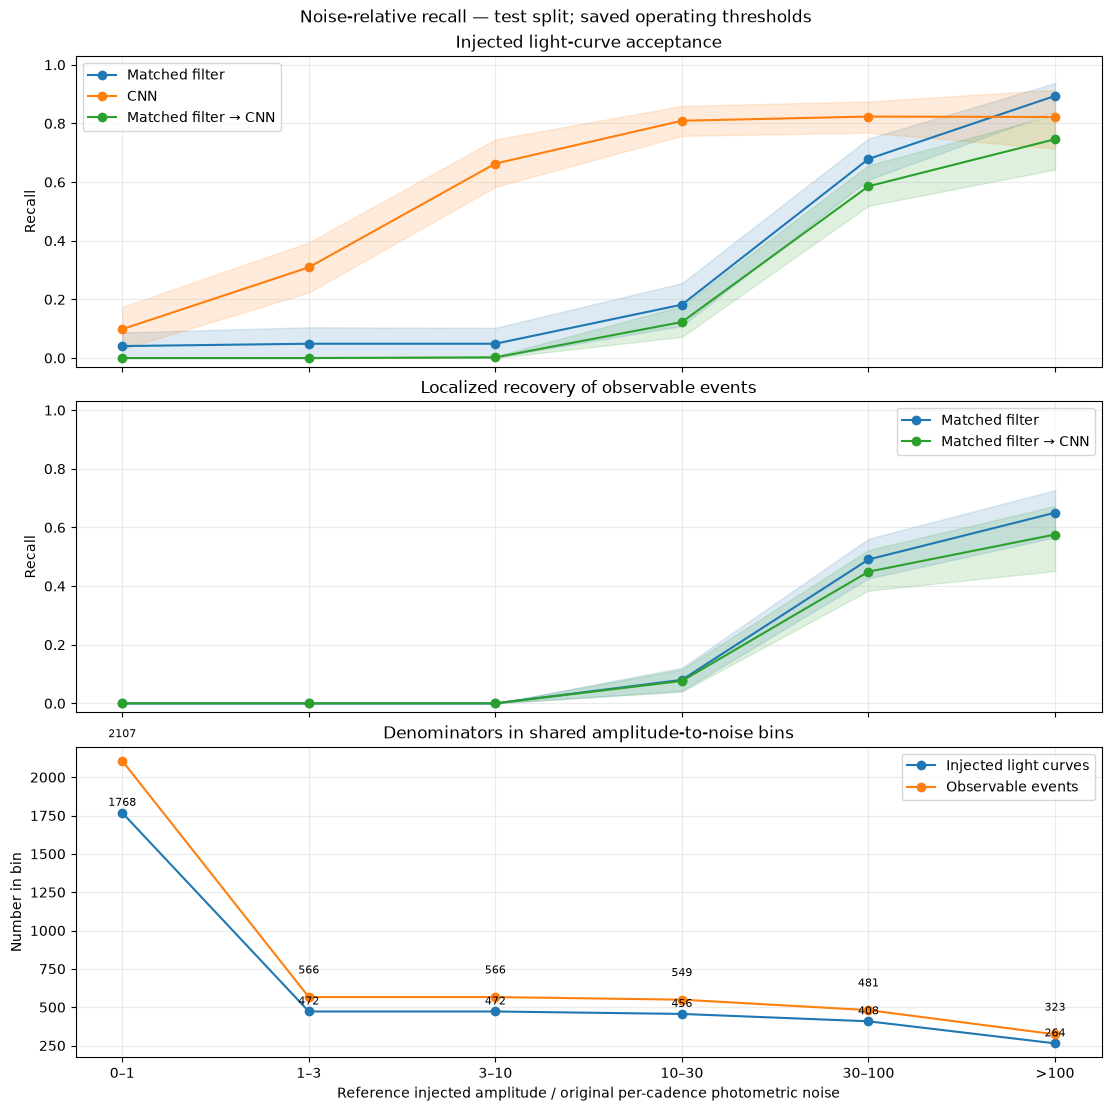

,method,low,high,center,bin,n,groups,recovered,recall,lower,upper,measure
0,matched_filter,0.0,1.0,0,0–1,1768,60,72,0.040724,0.000000,0.087367,light-curve acceptance
1,cnn,0.0,1.0,0,0–1,1768,60,174,0.098416,0.029869,0.174350,light-curve acceptance
2,combined,0.0,1.0,0,0–1,1768,60,0,0.000000,0.000000,0.000000,light-curve acceptance
3,matched_filter,1.0,3.0,1,1–3,472,59,23,0.048729,0.000000,0.104737,light-curve acceptance
4,cnn,1.0,3.0,1,1–3,472,59,146,0.309322,0.223497,0.393917,light-curve acceptance
5,combined,1.0,3.0,1,1–3,472,59,0,0.000000,0.000000,0.000000,light-curve acceptance
6,matched_filter,3.0,10.0,2,3–10,472,59,23,0.048729,0.002192,0.102992,light-curve acceptance
7,cnn,3.0,10.0,2,3–10,472,59,313,0.663136,0.583675,0.745617,light-curve acceptance
8,combined,3.0,10.0,2,3–10,472,59,1,0.002119,0.000000,0.006466,light-curve acceptance
9,matched_filter,10.0,30.0,3,10–30,456,57,83,0.182018,0.109356,0.255457,light-curve acceptance


,method,low,high,center,bin,n,groups,recovered,recall,lower,upper,measure
0,matched_filter,0.0,1.0,0,0–1,2107,60,0,0.000000,0.000000,0.000000,observable event recovery
1,combined,0.0,1.0,0,0–1,2107,60,0,0.000000,0.000000,0.000000,observable event recovery
2,matched_filter,1.0,3.0,1,1–3,566,59,0,0.000000,0.000000,0.000000,observable event recovery
3,combined,1.0,3.0,1,1–3,566,59,0,0.000000,0.000000,0.000000,observable event recovery
4,matched_filter,3.0,10.0,2,3–10,566,59,0,0.000000,0.000000,0.000000,observable event recovery
5,combined,3.0,10.0,2,3–10,566,59,0,0.000000,0.000000,0.000000,observable event recovery
6,matched_filter,10.0,30.0,3,10–30,549,57,44,0.080146,0.042646,0.121421,observable event recovery
7,combined,10.0,30.0,3,10–30,549,57,42,0.076503,0.039825,0.115670,observable event recovery
8,matched_filter,30.0,100.0,4,30–100,481,51,236,0.490644,0.425899,0.561396,observable event recovery
9,combined,30.0,100.0,4,30–100,481,51,216,0.449064,0.384352,0.522984,observable event recovery


In [8]:
# Rounded exploratory bins showing the CNN transition and high-ratio plateau.
noise_edges = np.array([0., 1., 3., 10., 30., 100., np.inf])
noise_bin_labels = ['0–1', '1–3', '3–10', '10–30', '30–100', '>100']

def noise_bin_mask(ratios, index):
    low, high = noise_edges[index:index + 2]
    return ((ratios >= low) if index == 0 else (ratios > low)) & (ratios <= high)

def noise_recall_bins(frame, keys, edges, repeats=NOISE_BOOTSTRAPS):
    records = []
    rng = np.random.default_rng(run.get('seed', 2401))
    groups = frame['group_id'].unique()
    for index, (low, high) in enumerate(zip(edges[:-1], edges[1:])):
        mask = noise_bin_mask(frame['amplitude_noise_ratio'], index)
        subset = frame.loc[mask]
        counts = subset.groupby('group_id').size().reindex(groups, fill_value=0).to_numpy()
        draws = rng.integers(0, len(groups), size=(repeats, len(groups)))
        denominators = counts[draws].sum(axis=1)
        for key in keys:
            successes = subset.groupby('group_id')[key].sum().reindex(groups, fill_value=0).to_numpy()
            valid = denominators > 0
            bootstrap = successes[draws].sum(axis=1)[valid] / denominators[valid]
            lower, upper = np.quantile(bootstrap, [.025, .975]) if len(bootstrap) else (np.nan, np.nan)
            records.append({'method': key, 'low': low, 'high': high, 'center': index, 'bin': noise_bin_labels[index],
                            'n': len(subset), 'groups': subset['group_id'].nunique(),
                            'recovered': int(subset[key].sum()),
                            'recall': subset[key].mean(), 'lower': lower, 'upper': upper})
    return pd.DataFrame(records)

if noise_acceptance.empty:
    print('No injections with valid original-control noise estimates.')
else:
    noise_acceptance_summary = noise_recall_bins(noise_acceptance, list(labels), noise_edges)
    noise_localized_summary = (noise_recall_bins(noise_localized, ['matched_filter', 'combined'], noise_edges)
                               if not noise_localized.empty else pd.DataFrame())
    fig, axes = plt.subplots(3, 1, figsize=(11, 11), sharex=True, constrained_layout=True)
    for ax, summary, title in [(axes[0], noise_acceptance_summary, 'Injected light-curve acceptance'),
                               (axes[1], noise_localized_summary, 'Localized recovery of observable events')]:
        if summary.empty:
            ax.text(.5, .5, 'No observable truth events', transform=ax.transAxes, ha='center')
        else:
            for key in summary['method'].unique():
                values = summary[summary['method'] == key]
                color = plt.get_cmap('tab10')(list(labels).index(key))
                line, = ax.plot(values['center'], values['recall'], marker='o', label=labels[key], color=color)
                ax.fill_between(values['center'], values['lower'], values['upper'], alpha=.15, color=line.get_color())
            ax.legend()
        ax.set(title=title, ylabel='Recall', ylim=(-.03, 1.03))
        ax.grid(alpha=.25)
    for summary, label in [(noise_acceptance_summary, 'Injected light curves'),
                           (noise_localized_summary, 'Observable events')]:
        if not summary.empty:
            counts = summary[summary['method'] == summary['method'].iloc[0]]
            axes[2].plot(counts['center'], counts['n'], marker='o', label=label)
            for _, value in counts.iterrows():
                axes[2].annotate(str(int(value['n'])), (value['center'], value['n']),
                                 xytext=(0, 5 if label == 'Injected light curves' else 17),
                                 textcoords='offset points', ha='center', fontsize=8)
    axes[2].set(xlabel='Reference injected amplitude / original per-cadence photometric noise',
                ylabel='Number in bin', title='Denominators in shared amplitude-to-noise bins')
    axes[2].set_xticks(range(len(noise_bin_labels)), noise_bin_labels)
    axes[2].legend()
    axes[2].grid(alpha=.25)
    fig.suptitle(f'Noise-relative recall — {NOISE_SPLIT} split; saved operating thresholds')
    plt.show()
    display(noise_acceptance_summary.assign(measure='light-curve acceptance'))
    if not noise_localized_summary.empty:
        display(noise_localized_summary.assign(measure='observable event recovery'))


## Confusion matrices by amplitude relative to noise

These panels use the same fixed **injected amplitude / original control noise**
bins as the noise-relative recall curves above. They measure saved light-curve
acceptance decisions at fixed operating thresholds, rather than localized recovery.
Each panel repeats all uninjected controls in `NOISE_SPLIT`, since controls have
no injected amplitude to assign to a ratio bin. Positive counts vary by bin;
negative counts therefore repeat and should not be summed across panels.
Cells show counts and percentages within each truth row, with a shared 0–100% scale.


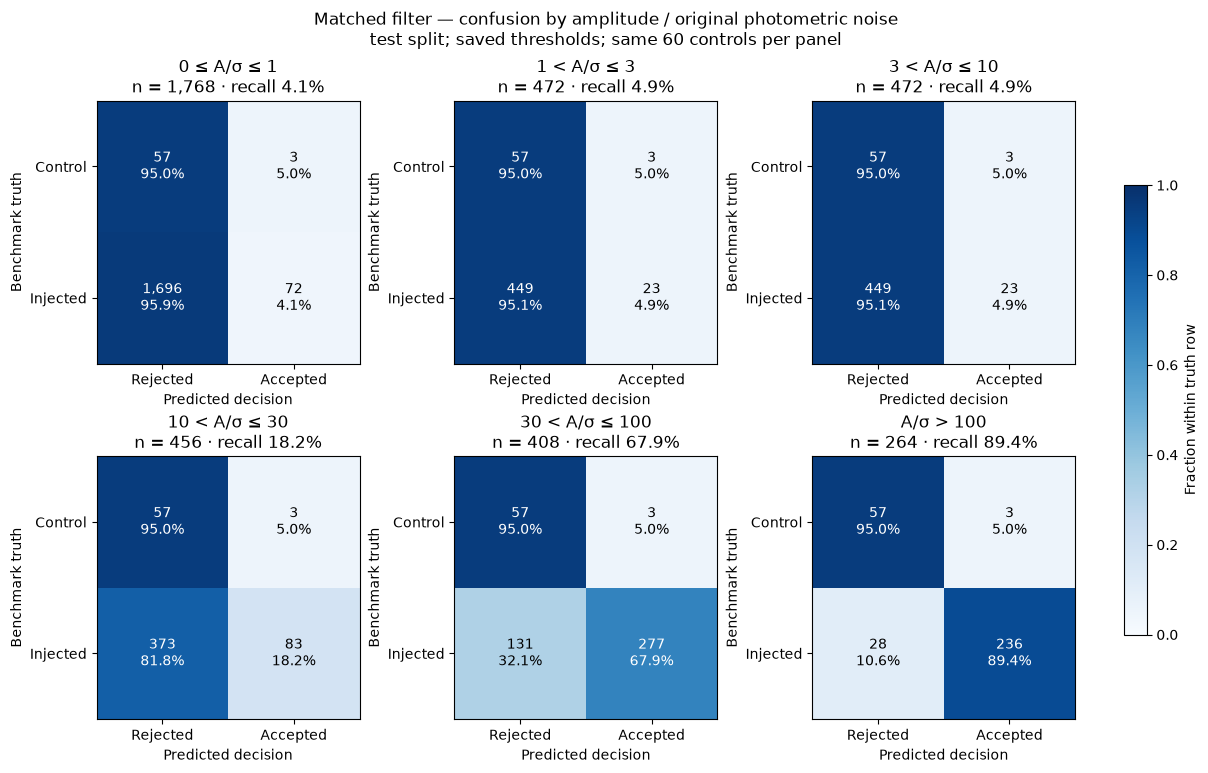

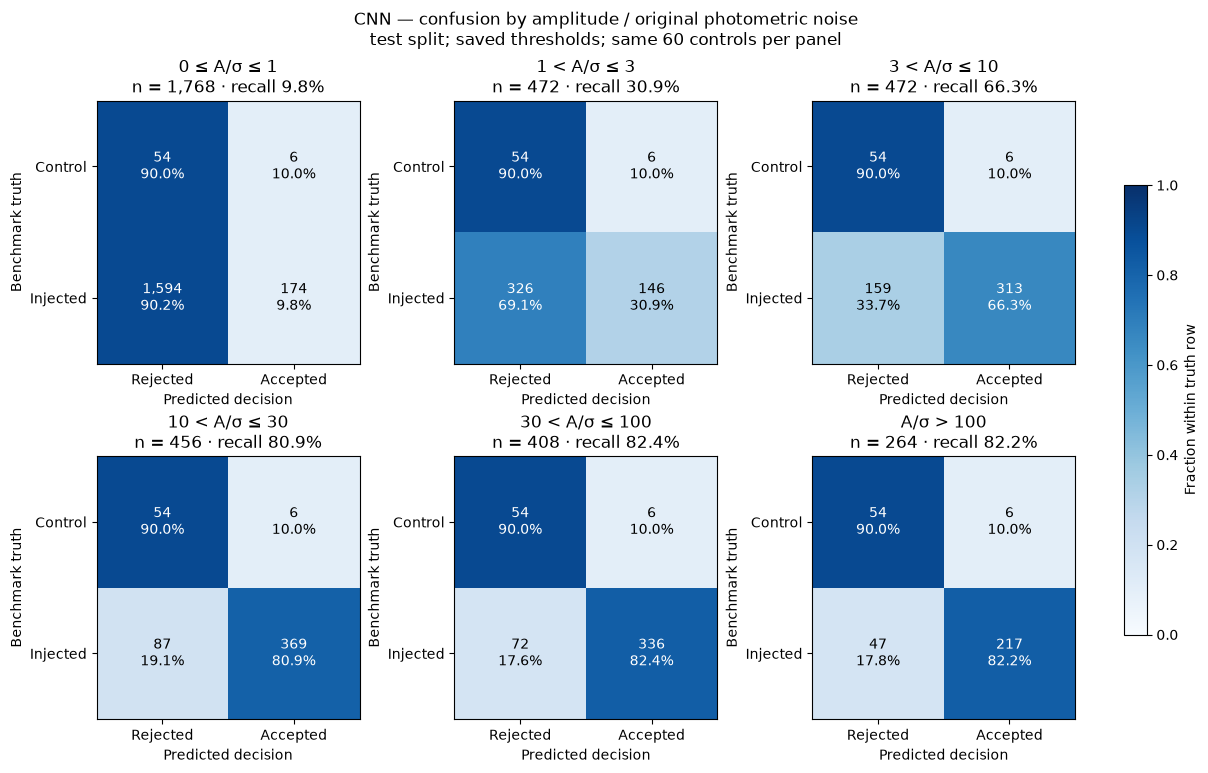

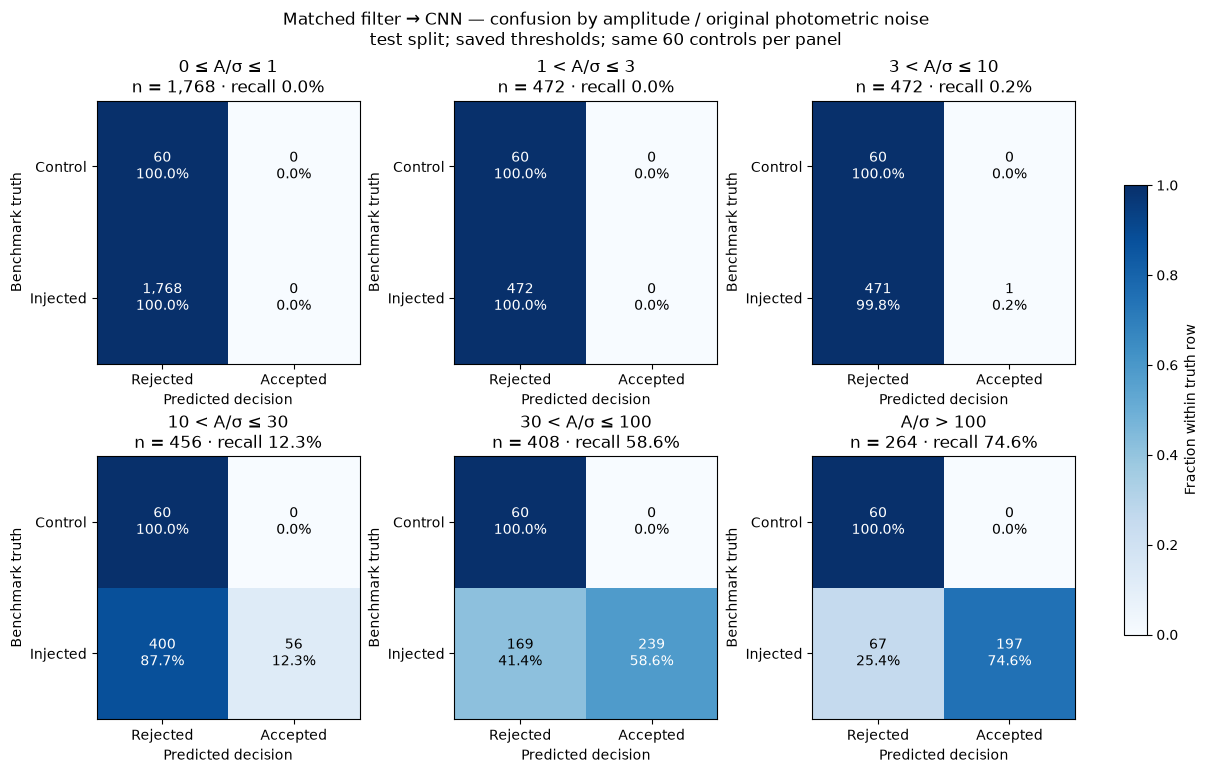

,method,bin,ratio_low,ratio_high,injections,controls,tn,fp,fn,tp,recall
0,Matched filter,0–1,0.0,1.0,1768,60,57,3,1696,72,0.040724
1,Matched filter,1–3,1.0,3.0,472,60,57,3,449,23,0.048729
2,Matched filter,3–10,3.0,10.0,472,60,57,3,449,23,0.048729
3,Matched filter,10–30,10.0,30.0,456,60,57,3,373,83,0.182018
4,Matched filter,30–100,30.0,100.0,408,60,57,3,131,277,0.678922
5,Matched filter,>100,100.0,inf,264,60,57,3,28,236,0.893939
6,CNN,0–1,0.0,1.0,1768,60,54,6,1594,174,0.098416
7,CNN,1–3,1.0,3.0,472,60,54,6,326,146,0.309322
8,CNN,3–10,3.0,10.0,472,60,54,6,159,313,0.663136
9,CNN,10–30,10.0,30.0,456,60,54,6,87,369,0.809211


In [9]:
noise_confusion_rows = []
if noise_acceptance.empty:
    print('No injections with valid original-control noise estimates.')
else:
    noise_confusion_controls = [r for r in scores if r['split'] == NOISE_SPLIT and r['truth'] == 0]
    for key, label in labels.items():
        bin_count = len(noise_edges) - 1
        columns = min(3, bin_count)
        rows = int(np.ceil(bin_count / columns))
        fig, axes = plt.subplots(rows, columns, figsize=(4 * columns, 3.8 * rows),
                                 squeeze=False, constrained_layout=True)
        tn = sum(not r[key]['accepted'] for r in noise_confusion_controls)
        fp = len(noise_confusion_controls) - tn
        for index, (low, high) in enumerate(zip(noise_edges[:-1], noise_edges[1:])):
            ax = axes.flat[index]
            ratios = noise_acceptance['amplitude_noise_ratio']
            mask = noise_bin_mask(ratios, index)
            injections = noise_acceptance.loc[mask]
            tp = int(injections[key].sum())
            fn = len(injections) - tp
            counts = np.array([[tn, fp], [fn, tp]])
            totals = counts.sum(axis=1, keepdims=True)
            fractions = np.divide(counts, totals, out=np.full((2, 2), np.nan), where=totals > 0)
            im = ax.imshow(fractions, vmin=0, vmax=1, cmap='Blues')
            for (i, j), count in np.ndenumerate(counts):
                percent = f'{fractions[i, j]:.1%}' if totals[i, 0] else 'undefined'
                ax.text(j, i, f'{count:,}\n{percent}', ha='center', va='center',
                        color='white' if fractions[i, j] > .55 else 'black')
            recall_label = f'{tp / len(injections):.1%}' if len(injections) else 'undefined'
            interval_label = ('0 ≤ A/σ ≤ 1' if index == 0 else
                              f'A/σ > {low:g}' if index == bin_count - 1 else
                              f'{low:g} < A/σ ≤ {high:g}')
            ax.set(xticks=[0, 1], yticks=[0, 1],
                   xticklabels=['Rejected', 'Accepted'], yticklabels=['Control', 'Injected'],
                   xlabel='Predicted decision', ylabel='Benchmark truth',
                   title=f'{interval_label}\n'
                         f'n = {len(injections):,} · recall {recall_label}')
            noise_confusion_rows.append({'method': label, 'bin': noise_bin_labels[index], 'ratio_low': low, 'ratio_high': high,
                                         'injections': len(injections), 'controls': len(noise_confusion_controls),
                                         'tn': tn, 'fp': fp, 'fn': fn, 'tp': tp,
                                         'recall': tp / len(injections) if len(injections) else np.nan})
        for ax in list(axes.flat)[bin_count:]:
            ax.set_visible(False)
        fig.suptitle(f'{label} — confusion by amplitude / original photometric noise\n'
                     f'{NOISE_SPLIT} split; saved thresholds; same {len(noise_confusion_controls)} controls per panel')
        fig.colorbar(im, ax=list(axes.flat), shrink=.7, label='Fraction within truth row')
        plt.show()
    noise_confusion_summary = pd.DataFrame(noise_confusion_rows)
    display(noise_confusion_summary)


## Injected/control examples

Choose `EXAMPLE` to inspect other saved test injections. The second panel shows
only the added signal. Saved observed timestamps include gaps. Background
candidates and missed high-amplitude injections deserve inspection.

tic410228347-sector1-cadence120-shape0-amp7 Recovered: False Observable: True


,method,score,threshold,curve_accepted
0,Matched filter,1242.223557,272.035371,True
1,CNN,0.999930,0.668387,True
2,Matched filter → CNN,0.331543,0.000000,True


Curve acceptance and localized event recovery are different measurements.


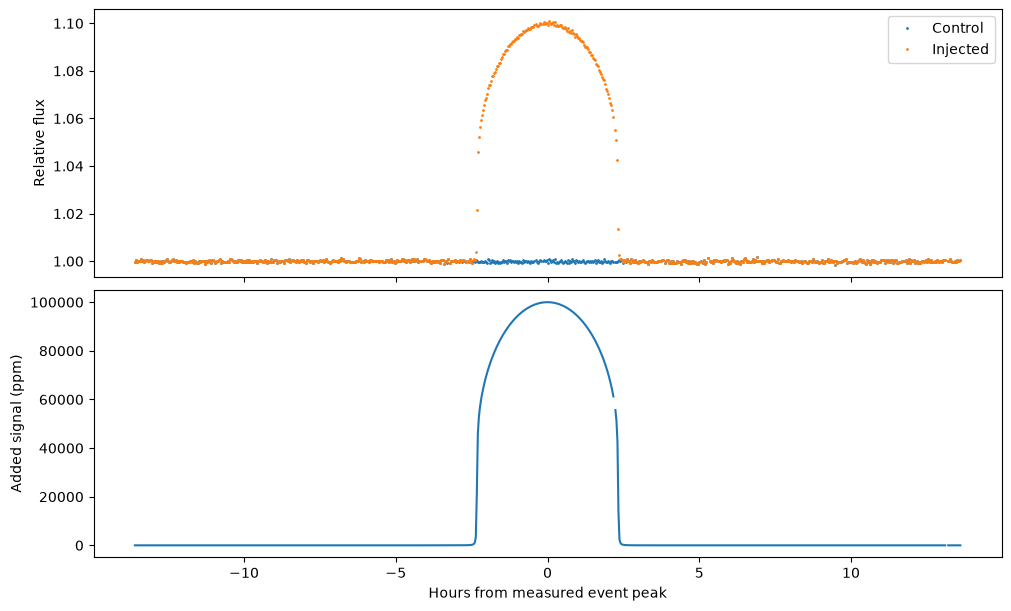

In [10]:
from searchlight.evaluation.preprocessing import read_lightcurve
samples = {s['sample_id']: s for s in manifest['samples']}
examples = [e for e in test_events if np.isclose(e['amplitude'] * 1e6, max(r['amplitude_ppm'] for r in sensitivity['rows']), rtol=1e-12)]
# Inspect strong, observable event misses first; these are diagnostic examples.
misses = [e for e in examples if e['observable'] and not e['combined_recovered']]
examples = misses or examples
EXAMPLE = 0
if examples:
    event = examples[EXAMPLE]
    sample = samples[event['sample_id']]
    injected = read_lightcurve(sample['source'])
    control = read_lightcurve(samples[sample['parent_id']]['source'])
    t = (injected.time - event['time']) * 24
    region = np.abs(t) <= 3 * event['duration_days'] * 24
    norm = np.nanmedian(control.flux)
    fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True, layout='constrained')
    ax[0].plot(t[region], control.flux[region] / norm, '.', ms=2, label='Control')
    ax[0].plot(t[region], injected.flux[region] / norm, '.', ms=2, label='Injected')
    ax[0].legend(); ax[0].set_ylabel('Relative flux')
    ax[1].plot(t[region], (injected.flux[region] - control.flux[region]) / norm * 1e6)
    ax[1].set(xlabel='Hours from measured event peak', ylabel='Added signal (ppm)')
    print(sample['sample_id'], 'Recovered:', event['combined_recovered'], 'Observable:', event['observable'])
    decision = next(row for row in scores if row['sample_id'] == sample['sample_id'])
    display(pd.DataFrame([{'method': labels[key], 'score': decision[key]['score'],
                           'threshold': run['thresholds'][key], 'curve_accepted': decision[key]['accepted']}
                          for key in labels]))
    print('Curve acceptance and localized event recovery are different measurements.')
    plt.show()

In [11]:
# Compact reproducibility record; detailed provenance is in results/run.json.
print('Physics:', run['dataset_metadata'].get('simulator'))
print('CNN:', run.get('cnn', {}).get('checkpoint_sha256'))
print('Templates:', run['template_sha256'])
print('Preprocessing:', run['preprocessing'])
print('Figures:', RESULTS / 'simple_evaluation.pdf')

print('CPU processes:', run.get('workers', 1), 'CNN processes:', run.get('cnn', {}).get('workers', 1))

print('Saved proposal distributions:', manifest.get('metadata', {}).get('sampling_distributions', 'not recorded in this historical run'))


Physics: {'selflensing': {'version': '0.0.1', 'direct_url': {'url': 'ssh://git@github.com/COBALT-lensing/py-self-lensing.git', 'vcs_info': {'vcs': 'git', 'commit_id': 'bfb8043aca508abff5174849a3fd8cb7ea561e7e'}}, 'commit_id': 'bfb8043aca508abff5174849a3fd8cb7ea561e7e'}, 'rustlens': {'version': '0.6.0', 'direct_url': None, 'commit_id': None}, 'jaxoplanet': {'version': '0.2.0', 'direct_url': None, 'commit_id': None}}
CNN: 36fa76961e6fdb95b4dbe1d6b8a86c9397b038ca3b3d16c0518c857399516a23
Templates: dd3cd03f5fca71493c5bfe31391a61279e943753cc8dd878c3259434f724eb77
Preprocessing: {'flux_product': 'PDCSAP_FLUX', 'quality_bitmask': -1, 'trim_start_hours': 0, 'normalize': True, 'detrend_window_days': None, 'gap_factor': 1.5, 'min_segment_points': 3, 'exposure_seconds': None}
Figures: /home/anm1u24/Code/astrosearchlight/evaluation_runs/full-evaluation-006/results/simple_evaluation.pdf
CPU processes: 1 CNN processes: 8
Saved proposal distributions: {'a': 'log_uniform', 'Macc': 'log_uniform', 'Mcom